In [79]:
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

# Use an explicit dark plotting style so figures remain readable in dark-mode
# notebook interfaces and when exported with a transparent background.
plt.style.use("dark_background")

# Audio extraction from cell phone video file:
# https://www.freeconvert.com/

sys_values = False
if sys_values:
    import sys
    print("sys.executable: ", sys.executable)
    print("-----------------")
    !type python
    print("-----------------")
    from pprint import pprint as p
    p(sys.path)


/var/folders/5f/rgfnh64x7k1bfzln9qq9n76r0000gr/T/ipykernel_40076/1533900658.py:30: UserWarning: PySoundFile failed. Trying audioread instead.
  x, sr = librosa.load(audio_path, sr=None)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/librosa/core/audio.py:183: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


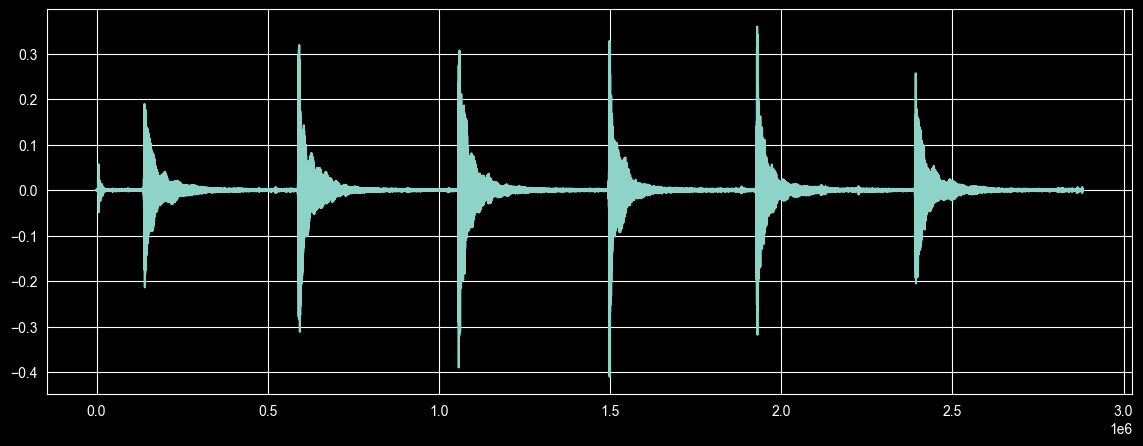

In [80]:
# Specify which audio file to look at, and where in the waveform
# the good signal begins ... the start times were initially set
# to zero and then adjusted later by viewing the waveforms.

choice = 8

if (choice == 1):
    audio_path = './LowE.mp4'
    start_time = 2.13
elif (choice == 2):
    audio_path = './MidE.mp4'
    start_time = 2.38
elif (choice == 3):
    audio_path = './HighE.mp4'
    start_time = 1.88
elif (choice == 4):
    audio_path = './sample1.mp4'
    start_time = 1.05
elif (choice == 5):
    audio_path = './sample2.mp4'
    start_time = 1.05
elif (choice == 6):
    audio_path = './IMG_6692.mp4'
elif (choice == 7):
    audio_path = './IMG_6693.mp4'
elif (choice == 8):
    audio_path = './IMG_6694.mp4'

# Get the waveform using librosa
x, sr = librosa.load(audio_path, sr=None)

# Plot the waveform
plt.figure(figsize=(14, 5))
plt.plot(x)

In [81]:
# Automatically locate the six chord attacks for the three chord recordings.
# A local maximum in a smoothed RMS envelope is much more stable than a local
# maximum of the raw waveform.  The six most prominent, well-separated maxima
# are retained and placed in chronological order.

if choice >= 6:
    chord_names = ["D", "G", "A", "Em", "Bm", "D"]
    root_notes = ["D3", "G2", "A2", "E2", "B2", "D3"]
    root_frequencies = [146.832, 97.999, 110.000, 82.407, 123.471, 146.832]

    # These are the only parameters normally worth adjusting for a new recording.
    window_duration = 5.0       # seconds of audio used for each FFT
    envelope_smoothing = 0.12   # seconds; suppresses sample-scale fluctuations
    minimum_separation = 6.0    # seconds; prevents two peaks from one chord
    number_of_chords = len(chord_names)

    envelope_hop = 512
    rms_envelope = librosa.feature.rms(
        y=x, frame_length=2048, hop_length=envelope_hop, center=True
    )[0]
    smoothing_frames = max(1, int(round(envelope_smoothing * sr / envelope_hop)))
    smoothing_kernel = np.ones(smoothing_frames) / smoothing_frames
    smoothed_envelope = np.convolve(rms_envelope, smoothing_kernel, mode="same")
    envelope_times = librosa.frames_to_time(
        np.arange(len(smoothed_envelope)), sr=sr, hop_length=envelope_hop
    )

    candidate_peaks, peak_properties = find_peaks(
        smoothed_envelope,
        distance=max(1, int(round(minimum_separation * sr / envelope_hop))),
        prominence=0,
    )
    if len(candidate_peaks) < number_of_chords:
        raise ValueError(
            f"Only {len(candidate_peaks)} separated amplitude peaks were found; "
            f"reduce minimum_separation (currently {minimum_separation:.1f} s)."
        )

    # Prominence measures how far a peak rises above its surroundings and is
    # more reliable than simply selecting the six largest amplitude values.
    strongest = np.argsort(peak_properties["prominences"])[-number_of_chords:]
    chord_peak_frames = np.sort(candidate_peaks[strongest])
    chord_peak_times = envelope_times[chord_peak_frames]

    # Standard-tuning voicings, from string 6 (low E) to string 1 (high E).
    # None denotes a muted string.
    chord_voicings = {
        "D":  [("6: muted", None), ("5: muted", None), ("4: D3", 146.832),
               ("3: A3", 220.000), ("2: D4", 293.665), ("1: F#4", 369.994)],
        "G":  [("6: G2", 97.999), ("5: B2", 123.471), ("4: D3", 146.832),
               ("3: G3", 195.998), ("2: B3", 246.942), ("1: G4", 391.995)],
        "A":  [("6: muted", None), ("5: A2", 110.000), ("4: E3", 164.814),
               ("3: A3", 220.000), ("2: C#4", 277.183), ("1: E4", 329.628)],
        "Em": [("6: E2", 82.407), ("5: B2", 123.471), ("4: E3", 164.814),
               ("3: G3", 195.998), ("2: B3", 246.942), ("1: E4", 329.628)],
        "Bm": [("6: muted", None), ("5: B2", 123.471), ("4: F#3", 184.997),
               ("3: B3", 246.942), ("2: D4", 293.665), ("1: F#4", 369.994)],
    }

    analysis_windows = []
    recording_duration = len(x) / sr
    for chord, root_note, root_hz, peak_time in zip(
        chord_names, root_notes, root_frequencies, chord_peak_times
    ):
        start = float(peak_time)
        end = min(start + window_duration, recording_duration)
        analysis_windows.append({
            "chord": chord,
            "start": start,
            "end": end,
            "root_note": root_note,
            "root_hz": root_hz,
            "strings": chord_voicings[chord],
        })
else:
    # Preserve the original two-window comparison for choices 1--5.
    if choice <= 3:
        myduration = 0.160
        myoffset = 3.20 - 2 * 0.320
    else:
        myduration = 2.2
        myoffset = 0.0
    analysis_windows = [
        {"chord": "Initial", "start": start_time, "end": start_time + myduration,
         "root_note": None, "root_hz": None, "strings": []},
        {"chord": "Final", "start": start_time + myoffset,
         "end": start_time + myoffset + myduration,
         "root_note": None, "root_hz": None, "strings": []},
    ]

for window in analysis_windows:
    first = int(round(window["start"] * sr))
    last = int(round(window["end"] * sr))
    window["samples"] = x[first:last]


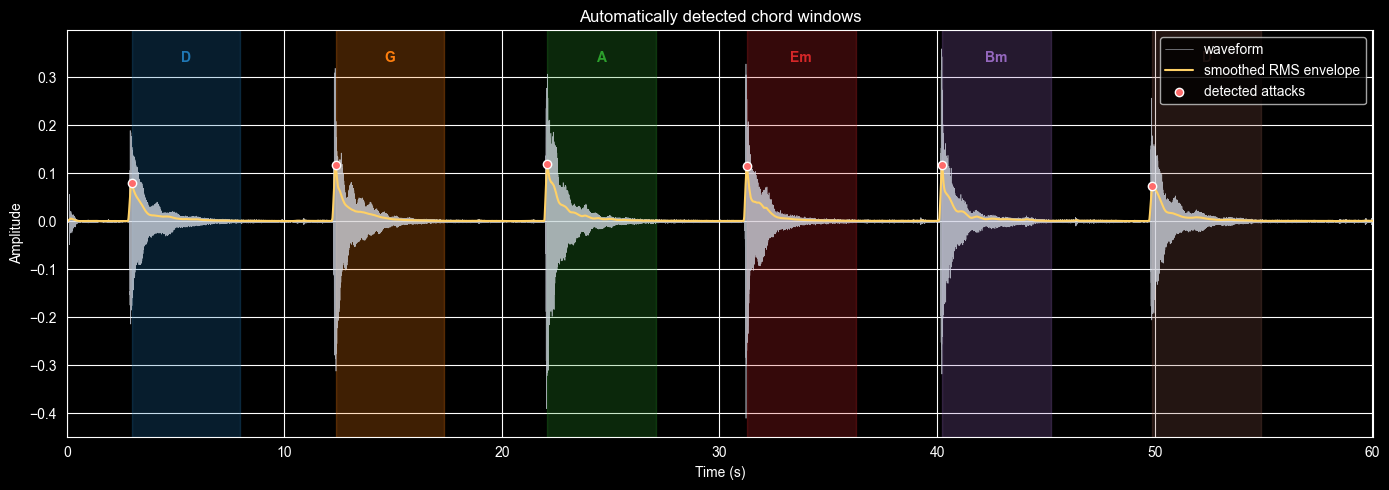

In [82]:
# Inspect the detected attacks and resulting analysis windows.
time = np.arange(len(x)) / sr
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(time, x, color="#d8dee9", linewidth=0.45, alpha=0.75, label="waveform")

if choice >= 6:
    ax.plot(
        envelope_times, smoothed_envelope, color="#ffd166", linewidth=1.5,
        label="smoothed RMS envelope"
    )
    ax.scatter(
        chord_peak_times, smoothed_envelope[chord_peak_frames],
        color="#ff6b6b", edgecolor="white", zorder=4, label="detected attacks"
    )

colors = plt.cm.tab10(np.arange(len(analysis_windows)))
for color, window in zip(colors, analysis_windows):
    ax.axvspan(window["start"], window["end"], color=color, alpha=0.25)
    ax.text(
        0.5 * (window["start"] + window["end"]),
        0.95,
        window["chord"],
        color=color,
        ha="center",
        va="top",
        fontweight="bold",
        transform=ax.get_xaxis_transform(),
    )

ax.set(xlabel="Time (s)", ylabel="Amplitude", title="Automatically detected chord windows")
ax.set_xlim(0, time[-1])
ax.legend(loc="upper right")
plt.tight_layout()


In [83]:
# Calculate a one-sided FFT for every chord.  Removing the mean suppresses
# the zero-frequency component; a Hann window reduces spectral leakage.
fft_results = []

for window in analysis_windows:
    samples = window["samples"]
    tapered = (samples - np.mean(samples)) * np.hanning(len(samples))
    spectrum = np.fft.rfft(tapered)
    frequencies = np.fft.rfftfreq(len(tapered), d=1.0 / sr)
    power = np.abs(spectrum) ** 2
    power_db = 10.0 * np.log10(np.maximum(power / power.max(), 1e-12))
    fft_results.append({**window, "frequencies": frequencies, "power_db": power_db})

print(f"Sample rate: {sr:,} Hz; Nyquist frequency: {sr / 2:,.0f} Hz")
for result in fft_results:
    root = f'{result["root_note"]} = {result["root_hz"]:.3f} Hz' if result["root_hz"] else "not specified"
    print(
        f'{result["chord"]:>2}: {result["start"]:5.2f}--{result["end"]:5.2f} s; '
        f'{len(result["samples"]) / sr:.2f} s analyzed; root {root}'
    )


Sample rate: 48,000 Hz; Nyquist frequency: 24,000 Hz
 D:  2.98-- 7.98 s; 5.00 s analyzed; root D3 = 146.832 Hz
 G: 12.35--17.35 s; 5.00 s analyzed; root G2 = 97.999 Hz
 A: 22.08--27.08 s; 5.00 s analyzed; root A2 = 110.000 Hz
Em: 31.25--36.25 s; 5.00 s analyzed; root E2 = 82.407 Hz
Bm: 40.23--45.23 s; 5.00 s analyzed; root B2 = 123.471 Hz
 D: 49.90--54.90 s; 5.00 s analyzed; root D3 = 146.832 Hz


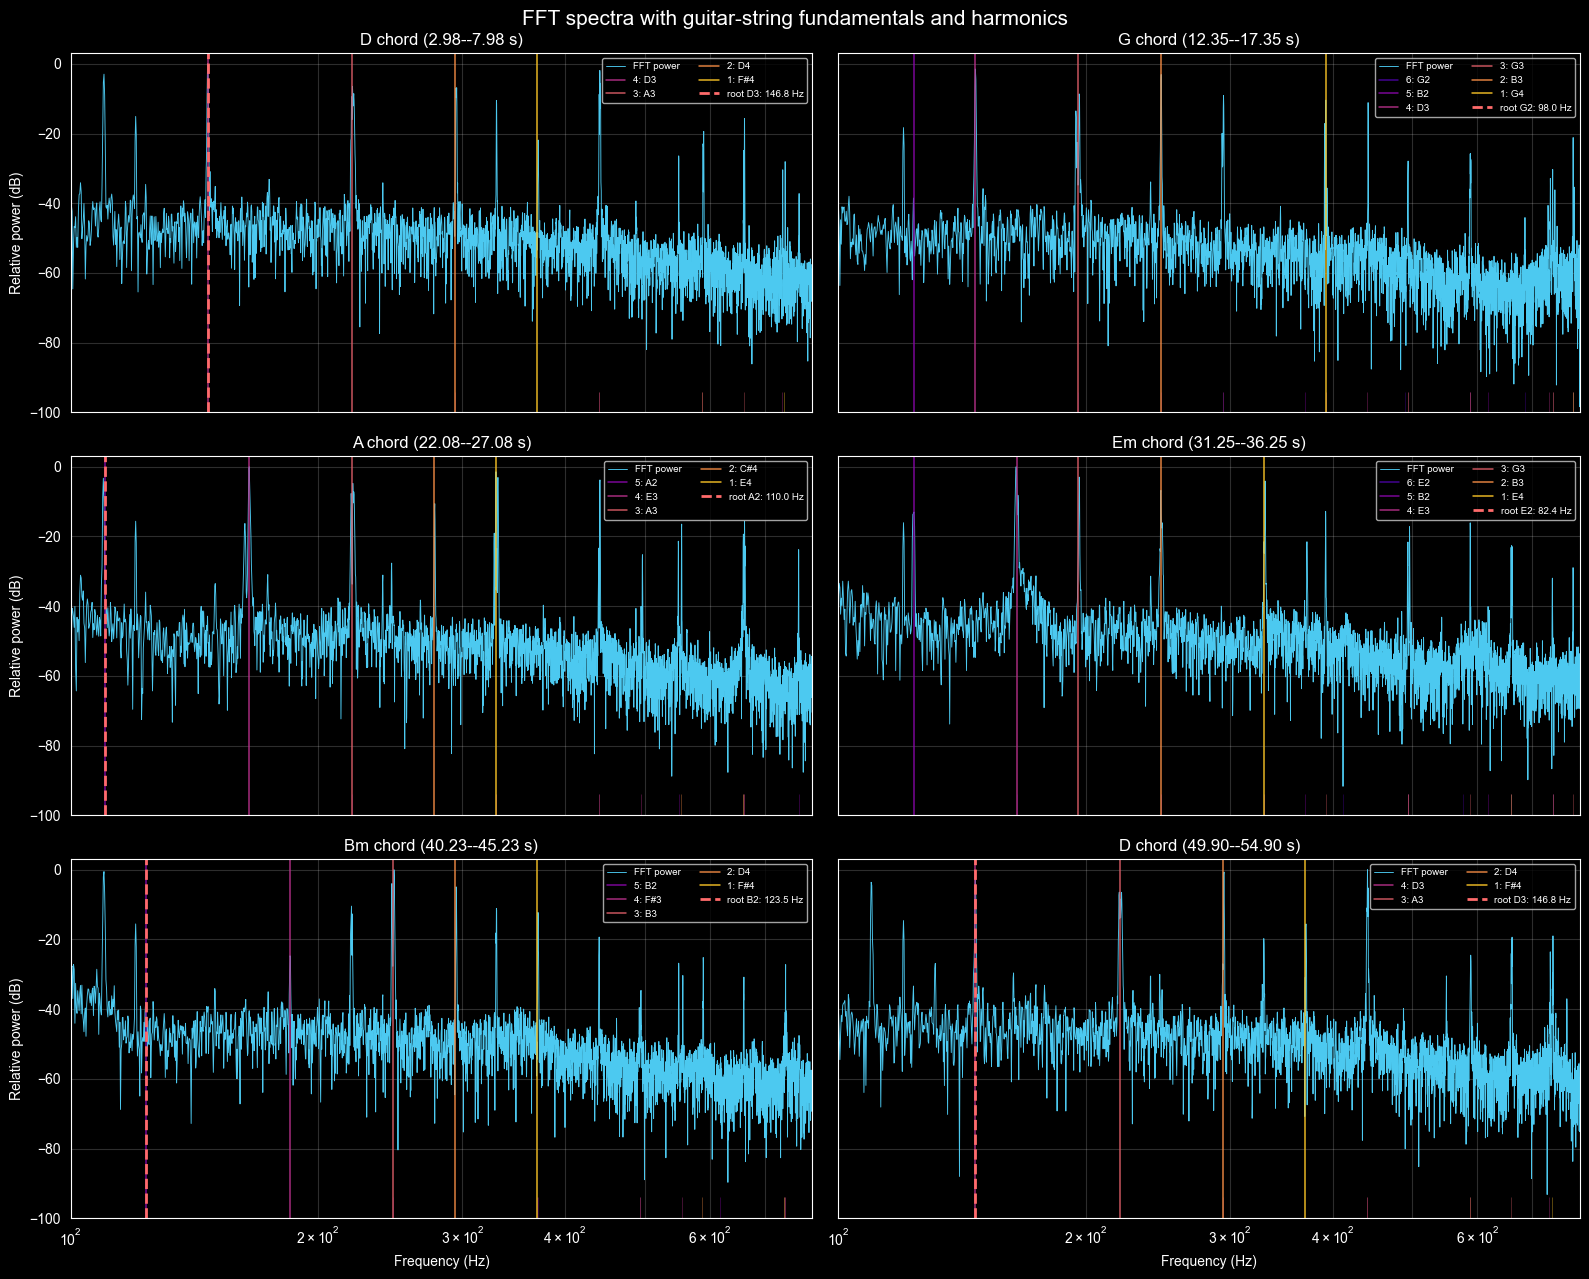

In [84]:
# Plot all six FFTs from 20 Hz to 20 kHz.  The FFT is normalized separately
# for each chord, so 0 dB is that chord's strongest spectral component.
#
# Solid colored lines: sounding-string fundamentals.
# Short marks at the bottom: every integer harmonic within the plotted range.
# Red dashed line: the selected root frequency for the chord.

frequency_min = 100.0
frequency_max = min(800.0, sr / 2.0)
string_colors = plt.cm.plasma(np.linspace(0.12, 0.88, 6))

fig, axes = plt.subplots(3, 2, figsize=(16, 13), sharex=True, sharey=True)
axes = axes.ravel()

for ax, result in zip(axes, fft_results):
    mask = (result["frequencies"] >= frequency_min) & (result["frequencies"] <= frequency_max)
    ax.semilogx(
        result["frequencies"][mask],
        result["power_db"][mask],
        color="#4cc9f0",
        linewidth=0.65,
        label="FFT power",
    )

    for string_index, (label, fundamental) in enumerate(result["strings"]):
        if fundamental is None:
            continue
        color = string_colors[string_index]
        ax.axvline(fundamental, color=color, linewidth=1.1, alpha=0.9, label=label)

        # Include all harmonics through 20 kHz as compact color-coded marks.
        harmonic_numbers = np.arange(2, int(frequency_max // fundamental) + 1)
        harmonics = fundamental * harmonic_numbers
        ax.vlines(harmonics, -100, -94, color=color, linewidth=0.45, alpha=0.55)

    if result["root_hz"] is not None:
        ax.axvline(
            result["root_hz"], color="#ff6b6b", linestyle="--", linewidth=2.0,
            label=f'root {result["root_note"]}: {result["root_hz"]:.1f} Hz'
        )

    ax.set_title(
        f'{result["chord"]} chord ({result["start"]:.2f}--{result["end"]:.2f} s)'
    )
    ax.set_xlim(frequency_min, frequency_max)
    ax.set_ylim(-100, 3)
    ax.grid(True, which="both", alpha=0.18)
    ax.legend(fontsize=7, ncol=2, loc="upper right")

for ax in axes[-2:]:
    ax.set_xlabel("Frequency (Hz)")
for ax in axes[::2]:
    ax.set_ylabel("Relative power (dB)")

fig.suptitle("FFT spectra with guitar-string fundamentals and harmonics", fontsize=15)
plt.tight_layout()


### Reading the plots

Each solid colored line is the fundamental frequency of one sounding string in the usual chord voicing. The red dashed line marks the selected root note. The short colored lines along the bottom show all integer harmonics of each string up to 20 kHz. Muted strings are kept in `chord_voicings` as `None` and are not plotted.

Because guitar strings excite shared chord tones at several octaves, many fundamentals and harmonics overlap. The measured peaks may also be slightly displaced by tuning, fingering pressure, and the frequency resolution of the selected time window.


## Chord-by-chord comparison of the three guitars

The following analysis loads all three recordings and applies the same automatic peak detection, window duration, and FFT calculation to each one. Each curve is normalized independently to 0 dB, so the comparison emphasizes **spectral shape and harmonic balance**, rather than recording level or microphone distance.

Choices 6, 7, and 8 are assumed to be the Taylor 710ce, Taylor 210ce Plus, and Takamine F375S, respectively. The first and final D chords are shown separately as repeated trials.


/var/folders/5f/rgfnh64x7k1bfzln9qq9n76r0000gr/T/ipykernel_40076/3768188687.py:14: UserWarning: PySoundFile failed. Trying audioread instead.
  signal, sample_rate = librosa.load(path, sr=None)


Automatically detected chord starts (seconds):
  Taylor 710ce: D (first): 3.36, G: 13.42, A: 21.33, Em: 30.94, Bm: 41.66, D (final): 51.55
  Taylor 210ce Plus: D (first): 3.56, G: 12.78, A: 22.76, Em: 30.17, Bm: 39.08, D (final): 45.76
  Takamine F375S: D (first): 2.98, G: 12.35, A: 22.08, Em: 31.25, Bm: 40.23, D (final): 49.90


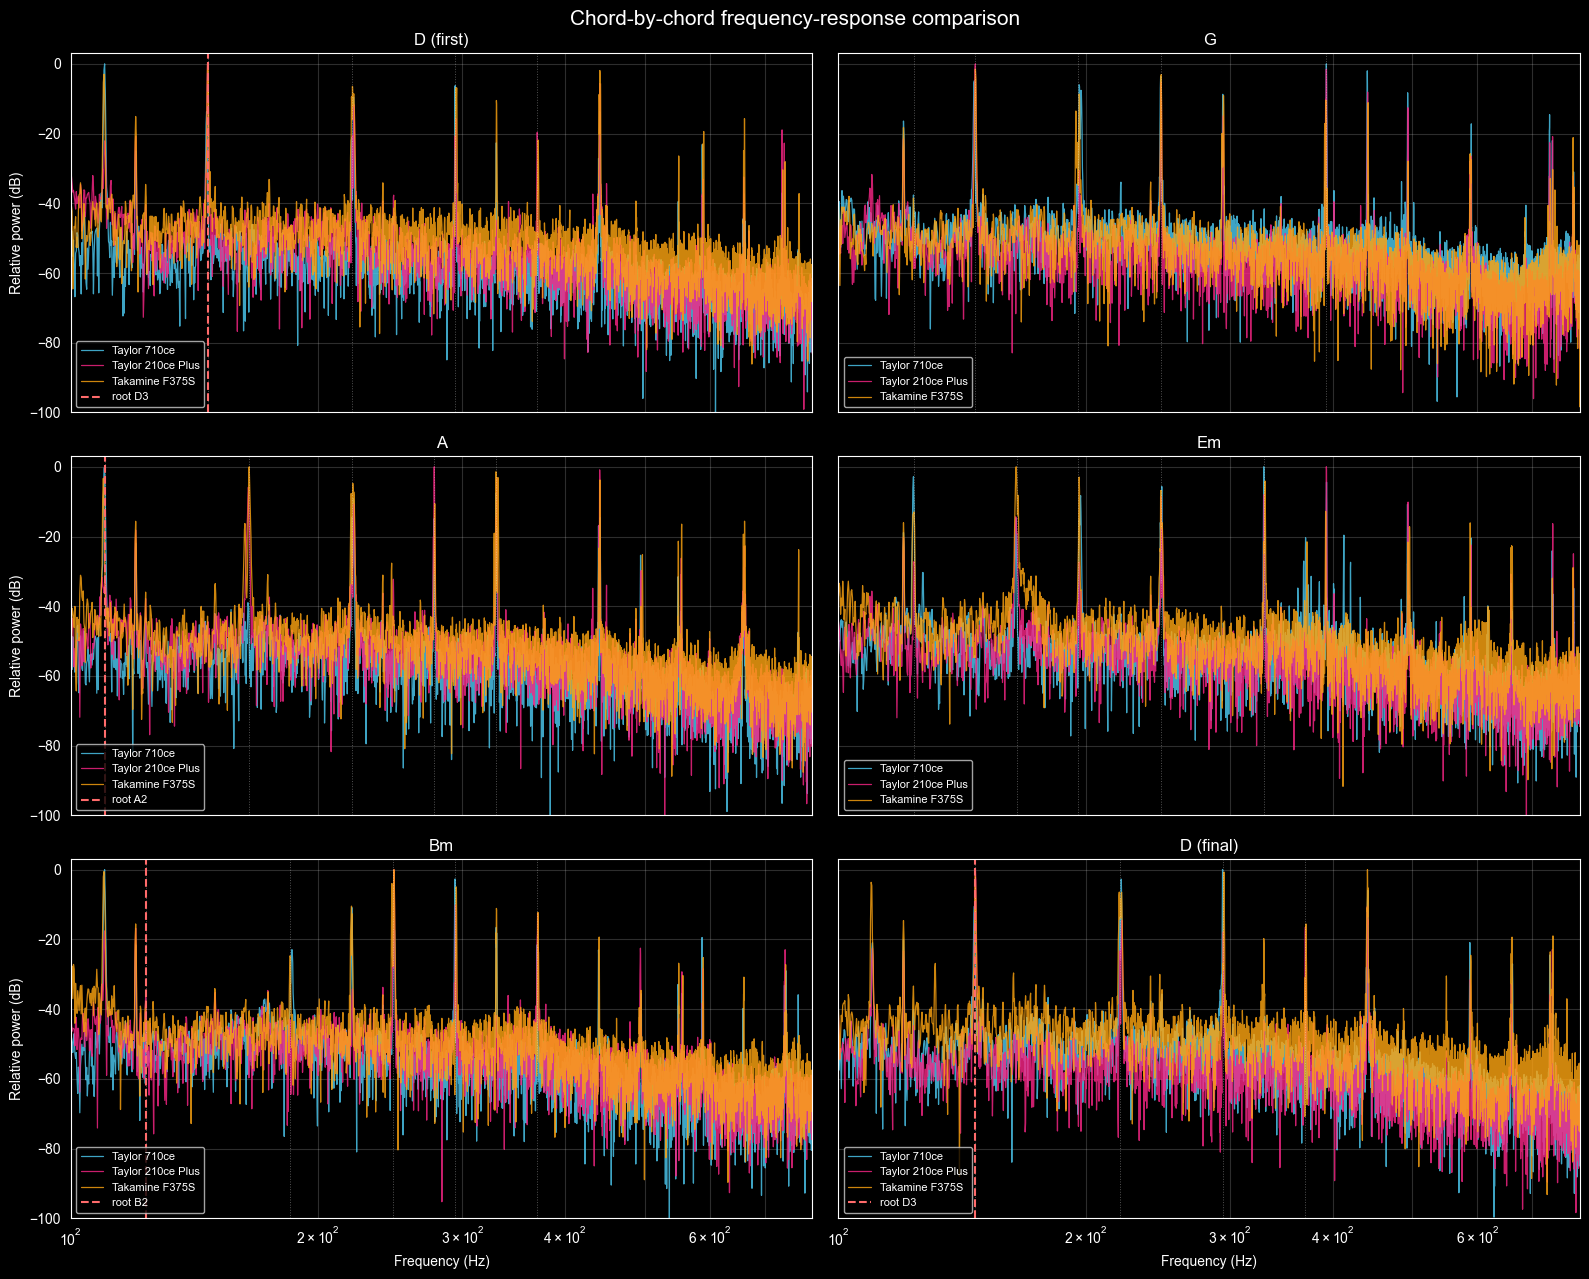

In [85]:
# Map each recording to its guitar.  Change names or files here if needed.
guitar_recordings = {
    "Taylor 710ce": "./IMG_6692.mp4",
    "Taylor 210ce Plus": "./IMG_6693.mp4",
    "Takamine F375S": "./IMG_6694.mp4",
}

comparison_chord_labels = ["D (first)", "G", "A", "Em", "Bm", "D (final)"]
guitar_colors = ["#4cc9f0", "#f72585", "#fca311"]


def analyze_chord_recording(path):
    # Detect six chord attacks and return normalized FFTs for one recording.
    signal, sample_rate = librosa.load(path, sr=None)

    rms = librosa.feature.rms(
        y=signal, frame_length=2048, hop_length=envelope_hop, center=True
    )[0]
    smooth_frames = max(1, int(round(envelope_smoothing * sample_rate / envelope_hop)))
    envelope = np.convolve(rms, np.ones(smooth_frames) / smooth_frames, mode="same")
    peaks, properties = find_peaks(
        envelope,
        distance=max(1, int(round(minimum_separation * sample_rate / envelope_hop))),
        prominence=0,
    )
    if len(peaks) < number_of_chords:
        raise ValueError(
            f"{path}: found only {len(peaks)} separated peaks; "
            "try reducing minimum_separation."
        )

    strongest = np.argsort(properties["prominences"])[-number_of_chords:]
    selected_peaks = np.sort(peaks[strongest])
    peak_times = librosa.frames_to_time(
        selected_peaks, sr=sample_rate, hop_length=envelope_hop
    )

    results = []
    for chord, label, root_note, root_hz, peak_time in zip(
        chord_names,
        comparison_chord_labels,
        root_notes,
        root_frequencies,
        peak_times,
    ):
        first = int(round(peak_time * sample_rate))
        last = min(first + int(round(window_duration * sample_rate)), len(signal))
        samples = signal[first:last]
        tapered = (samples - np.mean(samples)) * np.hanning(len(samples))
        spectrum = np.fft.rfft(tapered)
        frequencies = np.fft.rfftfreq(len(tapered), d=1.0 / sample_rate)
        power = np.abs(spectrum) ** 2
        power_db = 10.0 * np.log10(np.maximum(power / power.max(), 1e-12))
        results.append({
            "chord": chord,
            "label": label,
            "root_note": root_note,
            "root_hz": root_hz,
            "start": float(peak_time),
            "frequencies": frequencies,
            "power_db": power_db,
        })

    return results


# Process one file at a time; only the compact FFT results are retained.
guitar_fft_results = {
    guitar: analyze_chord_recording(path)
    for guitar, path in guitar_recordings.items()
}

print("Automatically detected chord starts (seconds):")
for guitar, results in guitar_fft_results.items():
    times = ", ".join(f'{result["label"]}: {result["start"]:.2f}' for result in results)
    print(f"  {guitar}: {times}")


# Overlay the three normalized spectra for each chord.
fig, axes = plt.subplots(3, 2, figsize=(16, 13), sharex=True, sharey=True)
axes = axes.ravel()

for chord_index, (ax, chord_label) in enumerate(zip(axes, comparison_chord_labels)):
    for (guitar, results), color in zip(guitar_fft_results.items(), guitar_colors):
        result = results[chord_index]
        mask = (
            (result["frequencies"] >= frequency_min)
            & (result["frequencies"] <= frequency_max)
        )
        ax.semilogx(
            result["frequencies"][mask],
            result["power_db"][mask],
            color=color,
            linewidth=0.9,
            alpha=0.82,
            label=guitar,
        )

    chord_name = chord_names[chord_index]
    for _, fundamental in chord_voicings[chord_name]:
        if fundamental is not None and frequency_min <= fundamental <= frequency_max:
            ax.axvline(fundamental, color="white", linestyle=":", linewidth=0.7, alpha=0.32)

    root_hz = root_frequencies[chord_index]
    if frequency_min <= root_hz <= frequency_max:
        ax.axvline(
            root_hz, color="#ff6b6b", linestyle="--", linewidth=1.5,
            label=f"root {root_notes[chord_index]}"
        )

    ax.set_title(chord_label)
    ax.set_xlim(frequency_min, frequency_max)
    ax.set_ylim(-100, 3)
    ax.grid(True, which="both", alpha=0.18)
    ax.legend(fontsize=8, loc="lower left")

for ax in axes[-2:]:
    ax.set_xlabel("Frequency (Hz)")
for ax in axes[::2]:
    ax.set_ylabel("Relative power (dB)")

fig.suptitle("Chord-by-chord frequency-response comparison", fontsize=15)
plt.tight_layout()


## Three-band frequency-response ratios relative to the Taylor 210ce Plus

The ratio comparison is divided into conventional three-band-EQ regions: **bass (20–250 Hz), midrange (250 Hz–2 kHz), and treble (2–20 kHz)**. These boundaries are useful defaults rather than universal standards, and they can be edited in `eq_bands` below.

Each guitar is normalized **once over the complete 20 Hz–20 kHz range**, using a logarithmically spaced frequency grid so each octave contributes equally to the mean. The same normalized ratio is then divided into three views. Normalizing each band separately would erase the broad bass-versus-midrange-versus-treble balance that these plots are intended to reveal.

The spectra use 1/24-octave smoothing before division. A value of 0 dB matches the normalized Taylor 210ce Plus response; positive values indicate a stronger relative response and negative values indicate a weaker relative response.


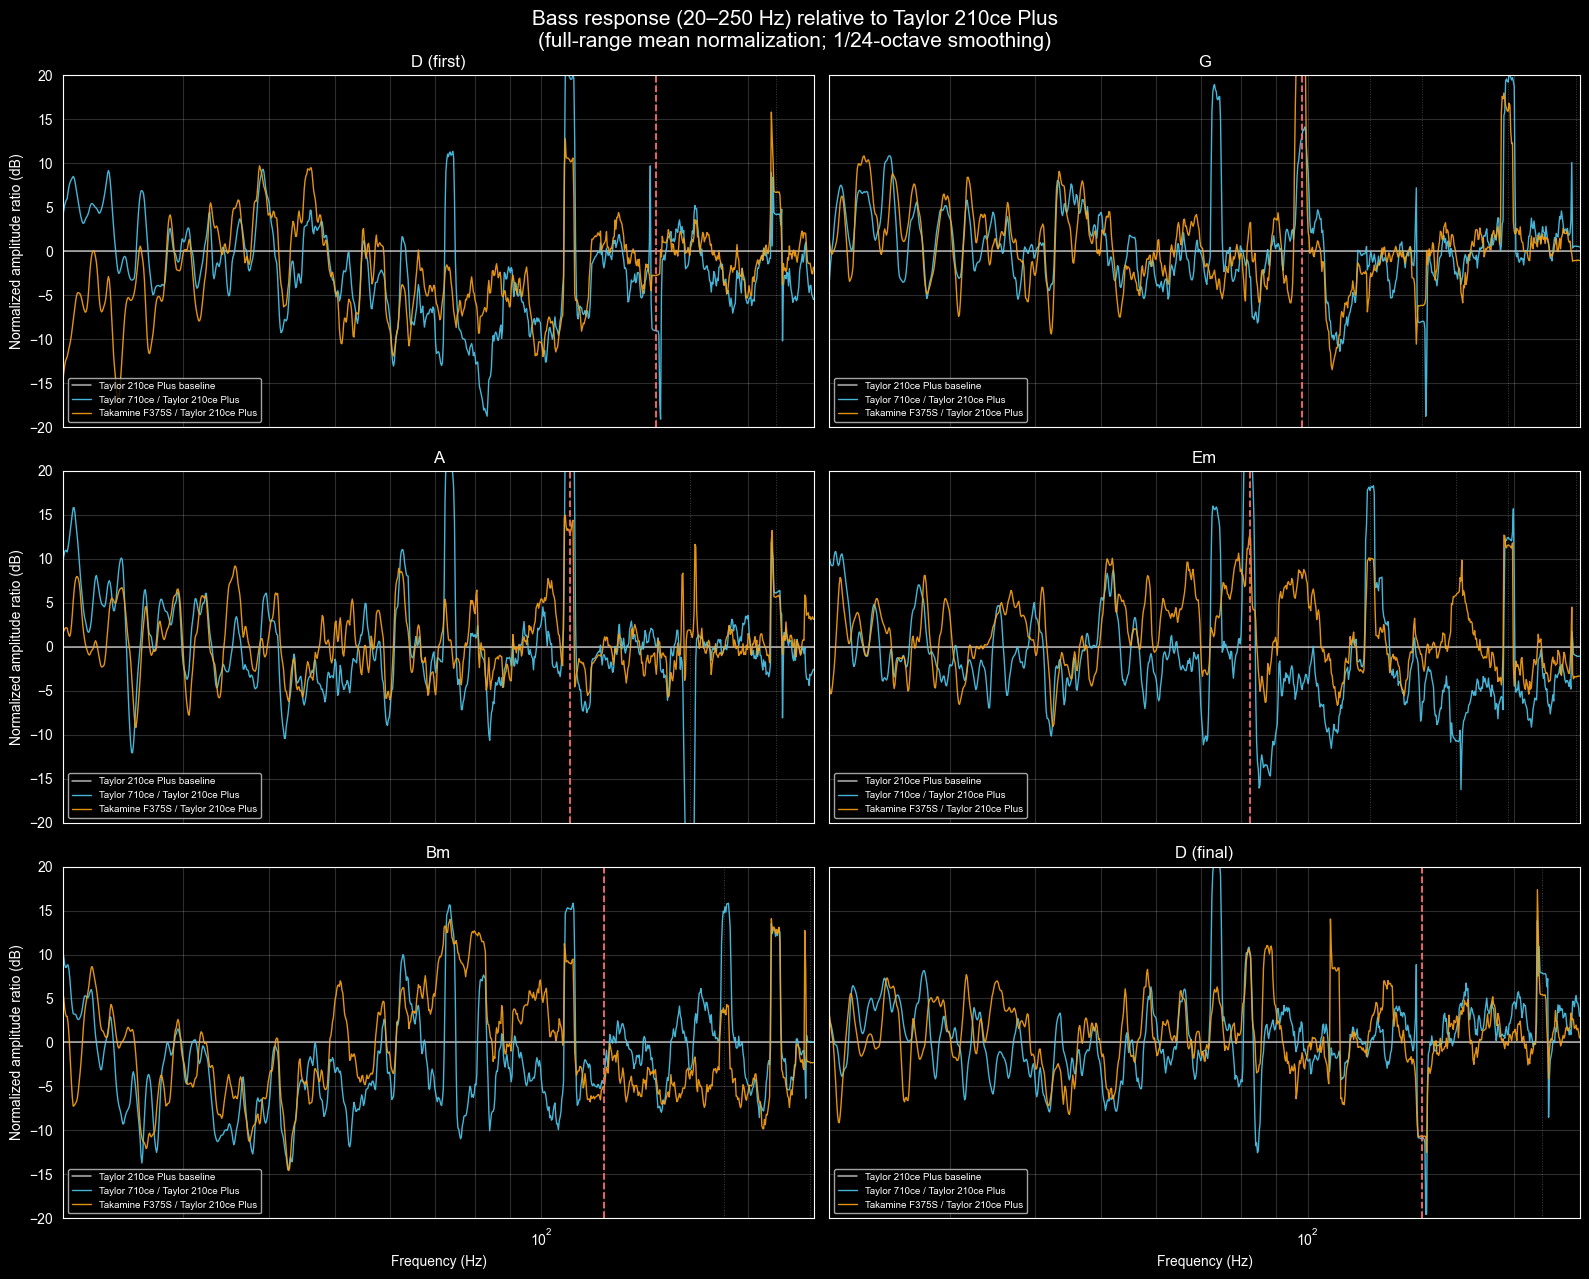

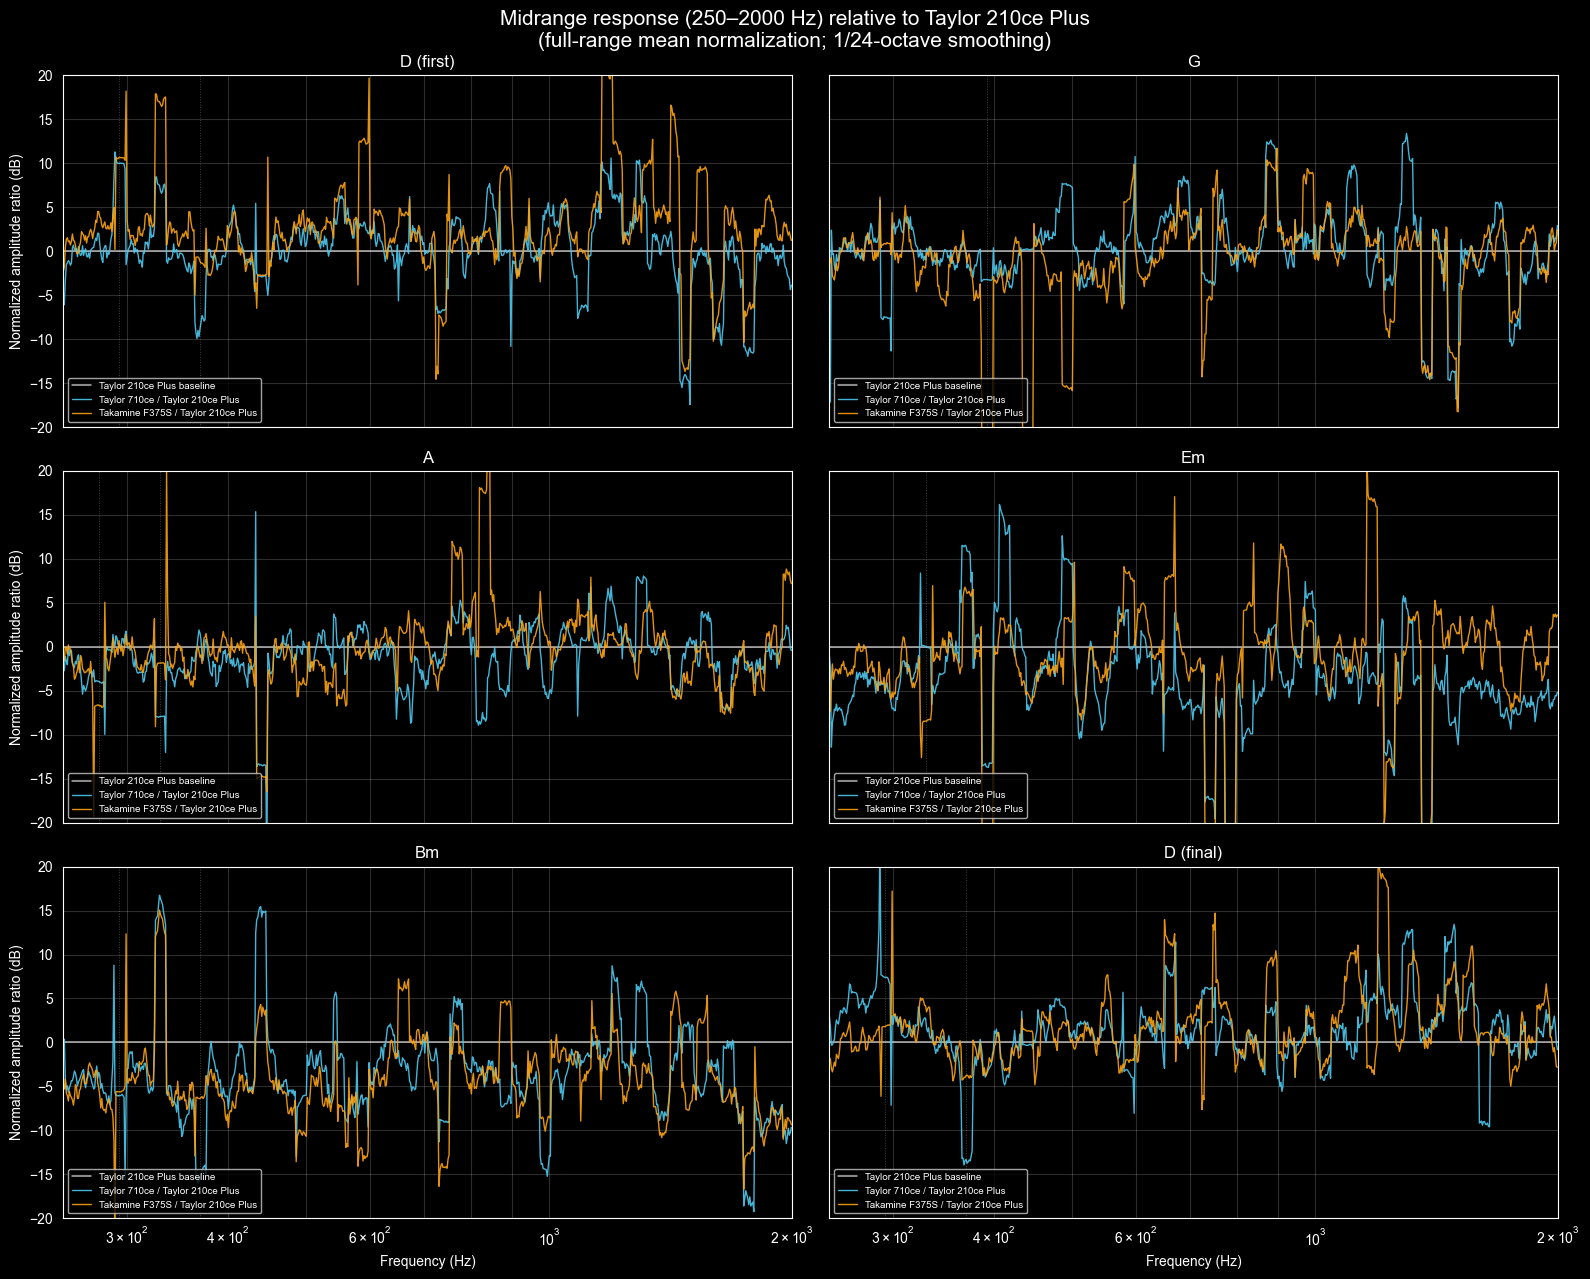

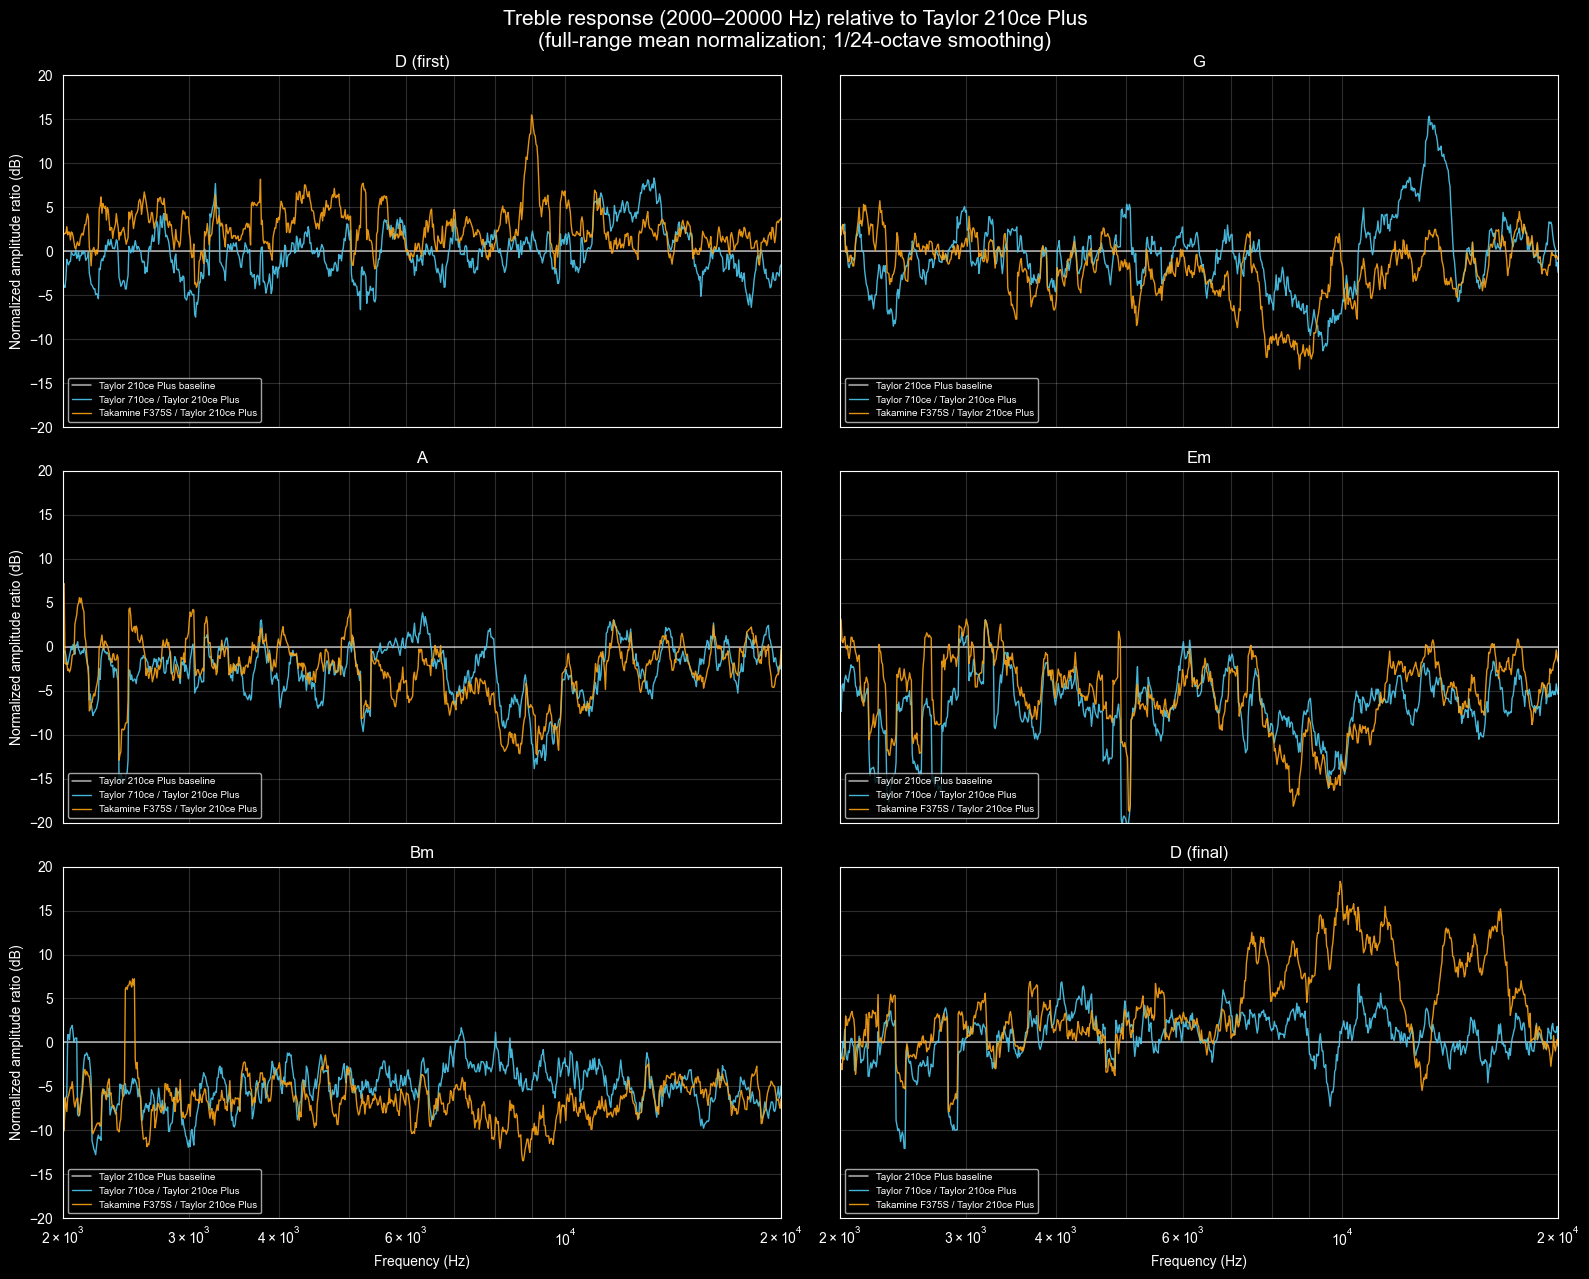

In [86]:
# Conventional three-band-EQ regions.  Adjust these boundaries if desired.
eq_bands = {
    "Bass": (20.0, 250.0),
    "Midrange": (250.0, 2_000.0),
    "Treble": (2_000.0, 20_000.0),
}

normalization_frequency_min = 20.0
normalization_frequency_max = min(20_000.0, sr / 2.0)
ratio_smoothing_octave_fraction = 24  # 24 means 1/24-octave smoothing
ratio_points_per_octave = 240
ratio_limit_db = 20.0
baseline_guitar = "Taylor 210ce Plus"


# A shared logarithmic grid gives equal weight to each octave when taking the
# mean and lets recordings with different FFT grids be compared safely.
number_of_octaves = np.log2(normalization_frequency_max / normalization_frequency_min)
number_of_ratio_points = int(np.ceil(number_of_octaves * ratio_points_per_octave)) + 1
ratio_frequencies = np.geomspace(
    normalization_frequency_min,
    normalization_frequency_max,
    number_of_ratio_points,
)


def smoothed_mean_normalized_amplitude(result):
    # power_db = 20 log10(amplitude / maximum amplitude), so this recovers a
    # linear relative-amplitude spectrum before smoothing and normalization.
    amplitude = 10.0 ** (result["power_db"] / 20.0)
    on_log_grid = np.interp(ratio_frequencies, result["frequencies"], amplitude)

    smoothing_bins = max(
        1,
        int(round(ratio_points_per_octave / ratio_smoothing_octave_fraction)),
    )
    if smoothing_bins % 2 == 0:
        smoothing_bins += 1
    kernel = np.ones(smoothing_bins) / smoothing_bins
    smoothed = np.convolve(on_log_grid, kernel, mode="same")

    mean_amplitude = np.mean(smoothed)
    if mean_amplitude <= 0:
        raise ValueError("Mean spectral amplitude must be positive.")
    return smoothed / mean_amplitude


# Normalize once over the full range, then reuse exactly the same responses in
# all three band plots.
normalized_amplitudes = {
    guitar: [smoothed_mean_normalized_amplitude(result) for result in results]
    for guitar, results in guitar_fft_results.items()
}

comparison_guitars = [guitar for guitar in guitar_recordings if guitar != baseline_guitar]
comparison_colors = {
    guitar: guitar_colors[list(guitar_recordings).index(guitar)]
    for guitar in comparison_guitars
}


for band_name, (band_min, band_max) in eq_bands.items():
    band_max = min(band_max, normalization_frequency_max)
    band_mask = (ratio_frequencies >= band_min) & (ratio_frequencies <= band_max)
    band_frequencies = ratio_frequencies[band_mask]

    fig, axes = plt.subplots(3, 2, figsize=(16, 13), sharex=True, sharey=True)
    axes = axes.ravel()

    for chord_index, (ax, chord_label) in enumerate(zip(axes, comparison_chord_labels)):
        baseline_amplitude = normalized_amplitudes[baseline_guitar][chord_index]

        # The reference divided by itself is exactly 0 dB.
        ax.axhline(
            0, color="white", linewidth=1.1, alpha=0.7,
            label=f"{baseline_guitar} baseline"
        )

        for guitar in comparison_guitars:
            guitar_amplitude = normalized_amplitudes[guitar][chord_index]
            amplitude_ratio = guitar_amplitude / np.maximum(baseline_amplitude, 1e-12)
            ratio_db = 20.0 * np.log10(np.maximum(amplitude_ratio, 1e-12))
            ax.semilogx(
                band_frequencies,
                ratio_db[band_mask],
                color=comparison_colors[guitar],
                linewidth=1.0,
                alpha=0.9,
                label=f"{guitar} / {baseline_guitar}",
            )

        chord_name = chord_names[chord_index]
        for _, fundamental in chord_voicings[chord_name]:
            if fundamental is not None and band_min <= fundamental <= band_max:
                ax.axvline(
                    fundamental, color="white", linestyle=":",
                    linewidth=0.7, alpha=0.25
                )

        root_hz = root_frequencies[chord_index]
        if band_min <= root_hz <= band_max:
            ax.axvline(root_hz, color="#ff6b6b", linestyle="--", linewidth=1.3)

        ax.set_title(chord_label)
        ax.set_xlim(band_min, band_max)
        ax.set_ylim(-ratio_limit_db, ratio_limit_db)
        ax.grid(True, which="both", alpha=0.18)
        ax.legend(fontsize=7, loc="lower left")

    for ax in axes[-2:]:
        ax.set_xlabel("Frequency (Hz)")
    for ax in axes[::2]:
        ax.set_ylabel("Normalized amplitude ratio (dB)")

    fig.suptitle(
        f"{band_name} response ({band_min:g}–{band_max:g} Hz) relative to {baseline_guitar}\n"
        f"(full-range mean normalization; 1/{ratio_smoothing_octave_fraction}-octave smoothing)",
        fontsize=15,
    )
    plt.tight_layout()
